# 第 4 课｜岗位聚类与项目交付

**90 分钟：原理与向量化 20′ → KMeans 30′ → 解释与聚焦分析 25′ → 项目汇报 15′**

目标：在数据相关候选岗位中，探索文本相似的岗位群，用关键词和代表职位解释聚类。
聚类是无监督探索，不是招聘预测，也没有“分类准确率”。若分群主要反映语言或公司模板，
这也是需要报告的发现，而不是强行命名成职业方向。

In [1]:
from pathlib import Path
import sys, json, re
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

# 支持从项目根目录、课程目录或 notebooks 目录启动。
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / 'course_utils.py').exists()), None)
if ROOT is None:
    ROOT = next((p / 'data_analysis202612' for p in candidates
                 if (p / 'data_analysis202612' / 'course_utils.py').exists()), None)
assert ROOT is not None, '请从项目根目录或课程目录启动 Jupyter'
sys.path.insert(0, str(ROOT))
from course_utils import *
pd.set_option('display.max_columns', 14)
pd.set_option('display.max_colwidth', 65)
pd.set_option('display.max_rows', 20)
print('课程目录：', ROOT)
print('Python：', sys.version.split()[0])
print('解释器：', sys.executable)

课程目录： /Users/luosen/WorkBuddy/JobsCrawler/data_analysis202612
Python： 3.10.16
解释器： /Users/luosen/WorkBuddy/JobsCrawler/data_analysis202612/.venv/bin/python


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import TruncatedSVD
from threadpoolctl import threadpool_limits
setup_plotting()
jobs = pd.read_parquet(DATA / 'processed' / 'jobs_features.parquet')
candidate = jobs.loc[jobs.focus_candidate & jobs.text_length.ge(40)].copy()
candidate['han_share'] = candidate['analysis_text'].map(
    lambda s: len(re.findall(r'[一-鿿]', s)) / max(1, len(re.findall(r'[a-zA-Z一-鿿]', s))))
# 此课聚焦中文为主的岗位；阈值是教学规则，不是经过训练的语言识别器。
focus = candidate.loc[candidate.han_share.ge(0.3)].copy()
intro_pattern = r'(?:团队|部门|公司)介绍[：:].*?(?=\s*1[、.．）)])'
intern_pattern = r'(?:日常实习|项目实习|转正实习)[：:][^。]*。'
focus['description_core'] = (focus['description_clean'].str.replace(intro_pattern, ' ', regex=True)
                             .str.replace(intern_pattern, ' ', regex=True))
focus['text_normalized'] = (focus['description_core'] + ' ' + focus['requirement_clean']).str.lower().str.replace(
    r'\s+', ' ', regex=True).str.strip()
# 只在有明确介绍标记和编号职责时移除介绍；无编号文本保留，避免贪婪删除。
assert re.sub(intro_pattern, ' ', '团队介绍：公司简介。 1、分析数据').strip() == '1、分析数据'
assert re.sub(intro_pattern, ' ', '团队介绍：无编号职责需保留') == '团队介绍：无编号职责需保留'
training = focus.drop_duplicates('text_normalized').copy()
print('初始候选：', len(candidate), '；语言范围外：', len(candidate)-len(focus))
print('中文为主候选：', len(focus), '；唯一文本：', len(training), '；重复文本：', len(focus)-len(training))
assert len(training) >= 50
display(training[['company_name', 'title_clean']].sample(10, random_state=SEED))

初始候选： 1138 ；语言范围外： 16
中文为主候选： 1122 ；唯一文本： 1028 ；重复文本： 94


,company_name,title_clean
17097,腾讯,商业分析师/商业分析经理（金融科技方向）
23702,阿里巴巴,阿里国际风险管理-风控数据分析-日常实习生
15118,字节跳动,商业化数据科学实习生-商业变现
4246,字节跳动,数据分析师（拉丁美洲）-国际电商
16560,字节跳动,算法实习生（数据湖基础设施与数据分析方向） - 火山方舟
16540,字节跳动,AI数据分析运营（生态方向）实习生 - TikTok
6483,字节跳动,数据分析专家（MaaS） - 火山方舟
10182,字节跳动,大促数据科学实习生 - 抖音电商
29465,美团,【LongCat大模型人才校招】基础模型 - 预训练数据策略和数据科学研究
25247,京东,数据科学岗


## 1. 先看一个失败基线，再改进表征

第一次试验使用原文字符2—4元片段，聚类中心充满编号、标点、公司介绍。
指标看起来更高，也未必对应职业方向。下面保留一个K=4的反例供课堂观察。

正式模型改用jieba分词，移除标点编号、常见套话和公司名称；只对中文字符占字母/汉字至少30%的候选训练。
英文为主职位留在全量分析表，另列排除数量，不能把中文子集结论推广到英文岗位。
公司/团队介绍仅在明确标记与编号职责之间删除，原文不覆盖，便于回查。
模型输入仍只有职责与要求，没有直接输入标题、公司和城市；残留模板依然可能影响分群。

In [3]:
baseline_vectorizer = TfidfVectorizer(analyzer='char', ngram_range=(2, 4), min_df=5, max_df=.8, max_features=6000)
baseline_X = baseline_vectorizer.fit_transform(training['analysis_text'])
with threadpool_limits(limits=1):
    baseline = KMeans(n_clusters=4, n_init=5, random_state=SEED).fit(baseline_X)
baseline_terms = baseline_vectorizer.get_feature_names_out()
baseline_terms_table = pd.DataFrame([
    {'cluster': i, 'top_fragments': repr(baseline_terms[np.argsort(center)[::-1][:8]].tolist())}
    for i, center in enumerate(baseline.cluster_centers_)])
display(baseline_terms_table)
csv_export(baseline_terms_table, '04_failed_char_baseline')

import jieba
stopwords = set('我们 你们 他们 以及 相关 工作 岗位 职责 要求 负责 具有 能够 良好 优秀 熟悉 优先 能力 以上 进行 包括 公司 团队 业务 经验 具备 使用 参与 通过 方向 支持 完成 基于 对于 了解 掌握 任职 本科 硕士 学历 职位 我们的 字节 跳动 字节跳动 抖音 今日头条 腾讯 美团 阿里巴巴 快手 小红书 京东 拼多多 滴滴 携程 tiktok bytedance about us and the of to in for with on is are be as or that you your our we will have at an a it can from this their global products team skills experience role work ability strong preferred responsibilities qualifications opportunity equal employment diversity inclusive inclusion candidate candidates disability reasonable accommodation accommodations provide needs request requests apply qualified applicants all people world join also more other which who was were has not one across development new including related good etc such years year degree bachelor master phd'.split())
for word in ['数据分析', '商业分析', '数据科学', '数据挖掘', '机器学习', '深度学习', '用户增长', '实验设计', '数据仓库',
             '指标体系', '因果推断', '数理统计', '数据建模', '可视化', '推荐算法', '经营分析', '数据治理', '数据产品', '统计分析', '增长策略']:
    jieba.add_word(word)

def tokenize(text):
    return [w for w in jieba.lcut(text.lower()) if w not in stopwords
            and re.fullmatch(r'[a-z][a-z0-9_+#.-]+|[一-鿿]{2,}', w)]

vectorizer = TfidfVectorizer(tokenizer=tokenize, token_pattern=None, min_df=5, max_df=.8,
                             max_features=4000, sublinear_tf=True)
X = vectorizer.fit_transform(training['text_normalized'])
assert (X.getnnz(axis=1) > 0).all(), '存在零向量，请检查文本/分词参数'
assert np.isfinite(X.data).all(), '向量包含非有限值'
csv_export(pd.DataFrame({'term': vectorizer.get_feature_names_out()}), '04_model_vocabulary')
print('训练矩阵：', X.shape, '；非零元素：', X.nnz)

,cluster,top_fragments
0,0,"['抖音', '团队', '实习', '提供', '用户', '； 2、', '20', '科学']"
1,1,"['. ', '1. ', '2. ', ' 2. ', '3. ', ' 3. ', ' 2.', '1.']"
2,2,"['ktok', 'tik', 'ikto', 'kto', 'kt', 'tikt', 'ikt', 'ik']"
3,3,"['产品', ' 2、', '2、', '1、', '据分', '数据分', '据分析', '数据分析']"


Building prefix dict from the default dictionary ...


Loading model from cache /var/folders/3q/wv1kfqy544v7lnd3d_75mg3w0000gn/T/jieba.cache


Loading model cost 0.225 seconds.


Prefix dict has been built successfully.


训练矩阵： (1028, 1678) ；非零元素： 85581


## 2. 比较 K=3、4、5、6，并检查稳定性

KMeans 将文本分成K群，最小化群内距离。固定种子让课堂结果可复现。
轮廓系数用于比较本次候选方案；分值低说明分群边界较弱，没有普适“合格线”。
同时检查最小群大小和两个随机种子下的 ARI（一致性指标，不是准确率）。
选择：优先保留最小群≥20且ARI≥0.6的方案，再取轮廓系数较高者；若无方案则回退并提示。
0.6是本课堂预设的稳定性筛选规则，不是行业通用标准。规则公开且可修改。
这只是起点，最终解释仍依赖代表文本审核。

,k,silhouette_cosine,inertia,smallest_cluster,seed_ARI
0,3,0.0346,881.9133,31,0.8969
1,4,0.0361,873.9095,30,0.4533
2,5,0.0349,867.6250,30,0.5962
3,6,0.0301,860.3261,27,0.4694


按预先声明规则选择 K = 3


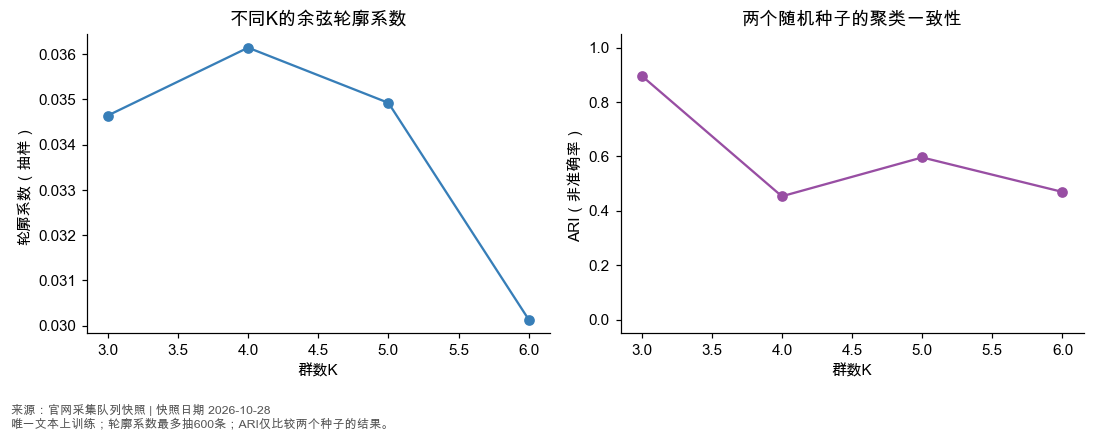

In [4]:
models, rows = {}, []
with threadpool_limits(limits=1):
    for k in [3, 4, 5, 6]:
        model = KMeans(n_clusters=k, random_state=SEED, n_init=10, max_iter=200)
        labels = model.fit_predict(X)
        assert np.isfinite(model.cluster_centers_).all() and np.isfinite(model.inertia_)
        other = KMeans(n_clusters=k, random_state=SEED+1, n_init=10, max_iter=200).fit_predict(X)
        score = silhouette_score(X, labels, metric='cosine', sample_size=min(600, X.shape[0]), random_state=SEED)
        models[k] = model
        rows.append({'k': k, 'silhouette_cosine': score, 'inertia': model.inertia_,
                     'smallest_cluster': int(np.bincount(labels).min()),
                     'seed_ARI': adjusted_rand_score(labels, other)})
comparison = pd.DataFrame(rows)
eligible = comparison.loc[comparison.smallest_cluster.ge(20) & comparison.seed_ARI.ge(0.6)]
if eligible.empty:
    eligible = comparison.loc[comparison.smallest_cluster.ge(20)]
    print('警示：没有方案满足稳定性门槛，仅作探索，需人工检查。')
if eligible.empty:
    eligible = comparison
    print('警示：所有方案都有小群，需人工检查。')
best_k = int(eligible.sort_values(['silhouette_cosine', 'k'], ascending=[False, True]).iloc[0]['k'])
model = models[best_k]
training['cluster'] = model.labels_
focus_X = vectorizer.transform(focus['text_normalized'])
focus['cluster'] = model.predict(focus_X)
display(comparison.round(4))
print('按预先声明规则选择 K =', best_k)
csv_export(comparison, '04_k_comparison')
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(comparison.k, comparison.silhouette_cosine, 'o-', color='#377eb8')
axes[0].set(title='不同K的余弦轮廓系数', xlabel='群数K', ylabel='轮廓系数（抽样）')
axes[1].plot(comparison.k, comparison.seed_ARI, 'o-', color='#984ea3')
axes[1].set(title='两个随机种子的聚类一致性', xlabel='群数K', ylabel='ARI（非准确率）', ylim=(-0.05, 1.05))
save_figure(fig, '04_model_comparison', '唯一文本上训练；轮廓系数最多抽600条；ARI仅比较两个种子的结果。')

## 3. 用关键词、代表岗位和公司集中度解释群

从每个中心取权重最高的词，并按到中心的欧氏距离找代表文本。
输出至少3条代表职位。`human_name`留给学生阅读后填写；`reference_name`是教师审阅当前快照代表岗位后给出的教学参考。
参考名称按关键词签名对应编号，不是模型识别出的职业真值，也未审核群内每一条职位。
模板化、来源结构和岗位级别都属于模型局限，不能凭一个词命名。

In [5]:
terms = vectorizer.get_feature_names_out()
distances = model.transform(X)
cluster_rows, examples = [], []
for cluster in range(best_k):
    indices = np.flatnonzero(training.cluster.to_numpy() == cluster)
    nearest = indices[np.argsort(distances[indices, cluster])[:3]]
    top_terms = terms[np.argsort(model.cluster_centers_[cluster])[::-1][:12]].tolist()
    assigned = focus.loc[focus.cluster.eq(cluster)]
    company_mix = assigned['company_name'].value_counts(normalize=True)
    cluster_rows.append({'cluster': cluster, 'unique_training_texts': len(indices), 'jobs': len(assigned),
                         'top_terms': ' / '.join(top_terms), 'largest_company': company_mix.index[0],
                         'largest_company_share': float(company_mix.iloc[0]), 'human_name': '待人工命名'})
    for idx in nearest:
        row = training.iloc[idx]
        examples.append({'cluster': cluster, 'job_key': row.job_key, 'company': row.company_name,
                         'title': row.title_clean, 'text_excerpt': row.analysis_text[:700],
                         'distance_to_center': float(distances[idx, cluster]), 'review_note': ''})
cluster_summary = pd.DataFrame(cluster_rows)
representatives = pd.DataFrame(examples)
# 以下参考解释来自教师对当前快照每群3条代表文本的审阅，不是自动职业真值。
# 按关键词签名对应群编号，避免编号本身被误认为具有业务含义。
def reference_interpretation(terms):
    if '异常情况' in terms and '脚本语言' in terms:
        return '电商分析实习模板倾向'
    if '商业分析' in terms and '行业' in terms:
        return '经营与商业分析倾向'
    if '实验' in terms and '模型' in terms:
        return '实验评估与模型分析倾向'
    return '待人工解释'

cluster_summary['reference_name'] = cluster_summary['top_terms'].map(reference_interpretation)
display(cluster_summary)
for cluster in range(best_k):
    display(Markdown(f'### 群 {cluster}：代表职位（先阅读，再命名）'))
    display(representatives.loc[representatives.cluster.eq(cluster), ['company', 'title', 'text_excerpt']])
csv_export(cluster_summary, '04_cluster_summary')
csv_export(representatives, '04_cluster_representatives')

,cluster,unique_training_texts,jobs,top_terms,largest_company,largest_company_share,human_name,reference_name
0,0,31,45,异常情况 / 协助 / 分析师 / 脚本语言 / 迅速 / 定量分析 / 定性 / 比较 / 至少 / 解读 / 深入分析...,字节跳动,1.000000,待人工命名,电商分析实习模板倾向
1,1,547,581,数据分析 / 行业 / 策略 / 问题 / 推动 / 落地 / 商业分析 / 运营 / 目标 / 工具 / 项目 / ai,字节跳动,0.263339,待人工命名,经营与商业分析倾向
2,2,450,496,优化 / 产品 / 实验 / 评估 / 模型 / 数据分析 / 策略 / 算法 / 用户 / 机器学习 / 问题 / 方法,字节跳动,0.612903,待人工命名,实验评估与模型分析倾向


### 群 0：代表职位（先阅读，再命名）

,company,title,text_excerpt
0,字节跳动,商家产品数据科学实习生 - TikTok Shop,团队介绍：TikTok Shop 是 TikTok 旗下的内容电商。平台汇聚全球优质商家与创作者，通过短视频、直播等多场景...
1,字节跳动,国际电商数据分析实习生（全托管） - TikTok Shop,团队介绍：TikTok Shop 是 TikTok 旗下的内容电商。平台汇聚全球优质商家与创作者，通过短视频、直播等多场景...
2,字节跳动,国际电商数据科学实习生 - TikTok Shop,团队介绍：TikTok Shop 是 TikTok 旗下的内容电商。平台汇聚全球优质商家与创作者，通过短视频、直播等多场景...


### 群 1：代表职位（先阅读，再命名）

,company,title,text_excerpt
3,字节跳动,印尼服务商业务数据分析师-TikTok Shop,1、服务商业务策略分析与优化支持：独立负责基于业务与运营数据，对服务商整体业务或专项项目进行系统性分析，全面评估业务表现，...
4,阿里巴巴,淘宝闪购-商业分析专家-用户营销,1、用户健康度诊断与机会洞察：搭建并持续迭代用户健康度评估体系，围绕用户规模、活跃、留存、价值分层等核心维度开展监测与诊断...
5,阿里巴巴,高德-资深商业分析师-本地生活交易方向,1. 负责本地生活交易增长与转化效率相关的商业分析工作，围绕业务增长、交易效率提升、供需分析、核心经营指标优化等多维度分析...


### 群 2：代表职位（先阅读，再命名）

,company,title,text_excerpt
6,字节跳动,数据分析师 - 抖音用户增长,团队介绍：抖音用户增长（User Growth）负责抖音、今日头条、番茄小说等多个产品的用户增长业务，建立行业领先的增长和...
7,字节跳动,数据科学 - TikTok,团队介绍：TikTok是一个覆盖150个国家和地区的国际短视频平台，我们希望通过TikTok发现真实、有趣的瞬间，让生活更...
8,字节跳动,数据科学 - TikTok研发,团队介绍：TikTok研发团队，旨在实现TikTok业务的研发工作，搭建及维护业界领先的产品。加入我们，你能接触到包括用户...


## 4. 聚焦分析：群体技能差异与二维投影

技能词典没有参与模型训练，可作为辅助解释，但与模型输入同来自文本，不能算独立真值验证。
二维SVD只展示高维文本的投影，不用肉眼看散点替代高维评估；类别颜色不表示优劣。

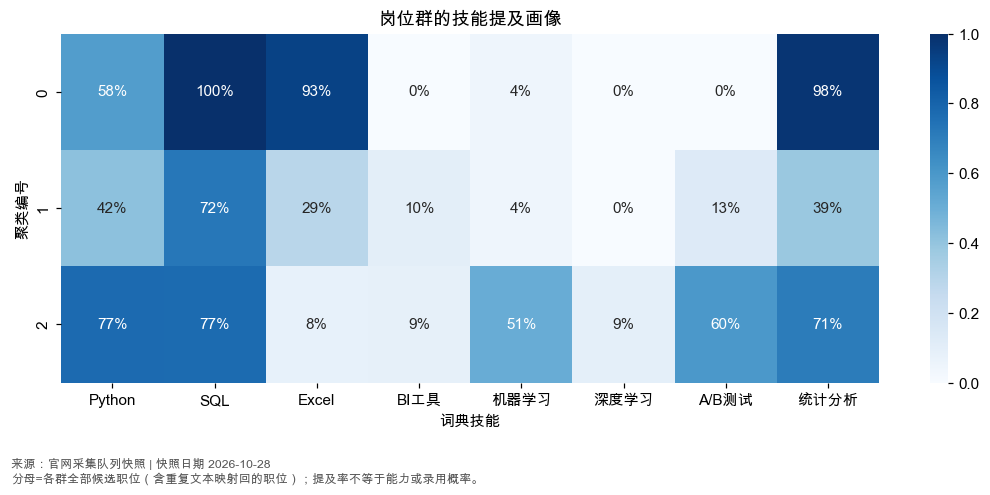

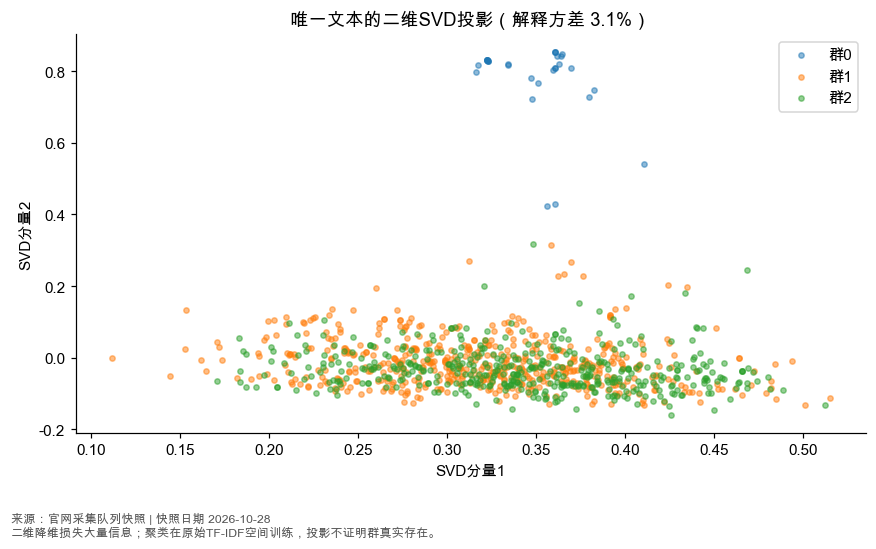

In [6]:
selected_skills = ['Python', 'SQL', 'Excel', 'BI工具', '机器学习', '深度学习', 'A/B测试', '统计分析']
profile = focus.groupby('cluster')[['skill_' + s for s in selected_skills]].mean()
profile.columns = selected_skills
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.heatmap(profile, annot=True, fmt='.0%', vmin=0, vmax=1, cmap='Blues', ax=ax)
ax.set(title='岗位群的技能提及画像', xlabel='词典技能', ylabel='聚类编号')
save_figure(fig, '04_cluster_skills', '分母=各群全部候选职位（含重复文本映射回的职位）；提及率不等于能力或录用概率。')
csv_export(profile.reset_index(), '04_cluster_skills')

projection = TruncatedSVD(n_components=2, random_state=SEED)
xy = projection.fit_transform(X)
assert np.isfinite(xy).all(), '二维投影包含非有限值'
fig, ax = plt.subplots(figsize=(8, 5))
for cluster in range(best_k):
    mask = training.cluster.to_numpy() == cluster
    ax.scatter(xy[mask, 0], xy[mask, 1], s=12, alpha=0.5, label=f'群{cluster}')
ax.set(title=f'唯一文本的二维SVD投影（解释方差 {projection.explained_variance_ratio_.sum():.1%}）',
       xlabel='SVD分量1', ylabel='SVD分量2')
ax.legend()
save_figure(fig, '04_cluster_projection', '二维降维损失大量信息；聚类在原始TF-IDF空间训练，投影不证明群真实存在。')

focus['cities_list'] = focus['cities'].map(json.loads)
cluster_cities = focus[['job_key', 'cluster', 'cities_list']].explode('cities_list').dropna(subset=['cities_list'])
cluster_city_counts = cluster_cities.groupby(['cluster', 'cities_list'], as_index=False).agg(jobs=('job_key', 'nunique'))
csv_export(cluster_city_counts, '04_cluster_city_counts')
csv_export(pd.crosstab(focus.cluster, focus.company_name).reset_index(), '04_cluster_company_counts')
assert len(focus) == cluster_summary.jobs.sum()
assert representatives.groupby('cluster').size().eq(3).all()

## 5. 形成报告与可写入简历的项目成果

报告中的数字自动来自前三课底稿和本课结果。手工命名与技能准确率未完成，不伪造。
把“发现一个可探索的群”与“证实一个真实职业类别”区分开来。
下一步行动：审核每群3条代表岗位和技能核验表，标记模板/语言影响，再决定调整分词或候选范围。

In [7]:
structure = json.loads((REPORTS / 'structure_metrics.json').read_text())
text_metrics = json.loads((REPORTS / 'text_metrics.json').read_text())
best = comparison.loc[comparison.k.eq(best_k)].iloc[0]
cluster_metrics = {'initial_candidates': len(candidate), 'excluded_language': len(candidate)-len(focus),
                   'candidate_jobs': len(focus), 'unique_texts': len(training), 'selected_k': best_k,
                   'silhouette_cosine': float(best.silhouette_cosine), 'seed_ARI': float(best.seed_ARI),
                   'svd_2d_variance': float(projection.explained_variance_ratio_.sum()),
                   'feature_count': X.shape[1], 'random_seed': SEED}
write_json(REPORTS / 'cluster_metrics.json', cluster_metrics)
focus.drop(columns=['cities_list']).to_parquet(DATA / 'processed' / 'jobs_clustered.parquet', index=False)

summary_lines = '\n'.join(f"- 群{int(r.cluster)}（参考：{r.reference_name}）：{int(r.jobs)}条职位；最大来源{r.largest_company}占{r.largest_company_share:.1%}。"
                          for r in cluster_summary.itertuples())
business_ids = cluster_summary.loc[cluster_summary.reference_name.eq('经营与商业分析倾向'), 'cluster']
model_ids = cluster_summary.loc[cluster_summary.reference_name.eq('实验评估与模型分析倾向'), 'cluster']
interpretation = '群名需要结合代表职位与岗位构成继续审核。'
if len(business_ids) == 1 and len(model_ids) == 1:
    b, m = int(business_ids.iloc[0]), int(model_ids.iloc[0])
    interpretation = (
        f'参考解释中，群{m}的机器学习提及率为{profile.loc[m, "机器学习"]:.1%}，'
        f'群{b}为{profile.loc[b, "机器学习"]:.1%}；'
        f'A/B测试提及率分别为{profile.loc[m, "A/B测试"]:.1%}和{profile.loc[b, "A/B测试"]:.1%}。'
        '这提示数据相关岗位存在技能侧重点差异，可用于进一步筛选岗位与安排学习重点；'
        '分群边界较弱，且公司、级别、招聘类型构成不同，不能当作确定职业分类或因果效应。')
report = f"""# 招聘职位样本分析｜课程项目报告

## 摘要与数据范围
固定快照包含 {structure['jobs']:,} 条待同步职位、{structure['companies']} 家公司。
原库只读，通过SQLite backup API建立一致快照；原文、校验摘要和清洗日志均归档。
样本不是整个招聘市场，也不一定全部仍在线；职位条目不等于招聘人数。

## 数据质量与结构发现
- {structure['top_company']}有{structure['top_company_jobs']:,}条，占样本{structure['top_company_share']:.1%}，来源结构不均衡。
- {structure['top_city']}覆盖{structure['top_city_jobs']:,}条职位，占全部职位{structure['top_city_coverage']:.1%}；多城市覆盖率不互斥。
- 字段覆盖率存在来源差异，学历缺失不能解释为无学历要求；本项目不报告薪资排行或市场增速。
- 日期可解析率、地理层级及缺失情况见01/02课质量底稿。

## 文本分析
标题规则筛出{text_metrics['focus_candidates']}条数据相关候选岗位。
候选中Python提及率{text_metrics['focus_python_rate']:.1%}、SQL相关词提及率{text_metrics['focus_sql_rate']:.1%}。
这是职责或要求的词典命中率；不是硬性要求率或个人能力评价。
已导出{text_metrics['manual_audit_rows']}条技能命中核验样本，尚未形成带人工真值的精确率/召回率。

## 岗位聚类探索
文本长度至少40的初始候选{len(candidate)}条；排除{len(candidate)-len(focus)}条英文为主的文本后，中文为主候选{len(focus)}条。
移除明确的团队介绍、套话并分词，按处理后文本去重得到{len(training)}条训练；词级TF-IDF，固定种子42。
字符n-gram失败基线主要反映编号/模板，保留为教学反例，不用于职业方向结论。
比较K=3/4/5/6，优先筛选最小群≥20且两个种子ARI≥0.6，再选轮廓系数最高的K={best_k}。
抽样余弦轮廓系数{best.silhouette_cosine:.3f}，两个随机种子的ARI={best.seed_ARI:.3f}。
这些指标用于模型内部比较，不是分类准确率；分群仍需人工解释。
{summary_lines}

### 聚焦发现与解释边界
{interpretation}
电商分析实习模板倾向群的代表岗位正文高度相似，不能视为独立验证出的通用职业类别。
参考名称来自每群3条代表文本的人工阅读，不是对群内全部岗位的完整标注。
虽然随机种子一致性较高，轮廓系数仍较低；稳定的结果不一定有清晰职业边界。

## 可执行后续行动
1. 为每群阅读3条代表文本，填写群名称、命名理由、模板或语言影响，再决定是否保留分群。
2. 完成技能核验表的人工标注，另外抽取未命中样本，审核误报和漏报后迭代词典。
3. 对需要比较的岗位先限定招聘类型、语言与级别，并在图表中显示样本量，避免构成混杂。

## 局限与复现
京东社招采集汇总显示中断；各来源批次和采集规则不同；历史职位保留；队列不是永久全量仓库。
城市是规则清洗后的候选，省级和待核验地点不进入城市榜；词典、经验/学历正则并非完美标注。
聚类可能反映公司、语言或模板；二维投影不代表高维可分性；未作因果推断。
依次运行四本Notebook；环境版本见requirements-lock.txt；原始快照SHA见data/raw/manifest.json。
"""
(REPORTS / '项目分析报告.md').write_text(report, encoding='utf-8')
display(Markdown(report))

# 招聘职位样本分析｜课程项目报告

## 摘要与数据范围
固定快照包含 40,661 条待同步职位、16 家公司。
原库只读，通过SQLite backup API建立一致快照；原文、校验摘要和清洗日志均归档。
样本不是整个招聘市场，也不一定全部仍在线；职位条目不等于招聘人数。

## 数据质量与结构发现
- 字节跳动有17,053条，占样本41.9%，来源结构不均衡。
- 北京覆盖19,363条职位，占全部职位47.6%；多城市覆盖率不互斥。
- 字段覆盖率存在来源差异，学历缺失不能解释为无学历要求；本项目不报告薪资排行或市场增速。
- 日期可解析率、地理层级及缺失情况见01/02课质量底稿。

## 文本分析
标题规则筛出1138条数据相关候选岗位。
候选中Python提及率58.4%、SQL相关词提及率75.6%。
这是职责或要求的词典命中率；不是硬性要求率或个人能力评价。
已导出54条技能命中核验样本，尚未形成带人工真值的精确率/召回率。

## 岗位聚类探索
文本长度至少40的初始候选1138条；排除16条英文为主的文本后，中文为主候选1122条。
移除明确的团队介绍、套话并分词，按处理后文本去重得到1028条训练；词级TF-IDF，固定种子42。
字符n-gram失败基线主要反映编号/模板，保留为教学反例，不用于职业方向结论。
比较K=3/4/5/6，优先筛选最小群≥20且两个种子ARI≥0.6，再选轮廓系数最高的K=3。
抽样余弦轮廓系数0.035，两个随机种子的ARI=0.897。
这些指标用于模型内部比较，不是分类准确率；分群仍需人工解释。
- 群0（参考：电商分析实习模板倾向）：45条职位；最大来源字节跳动占100.0%。
- 群1（参考：经营与商业分析倾向）：581条职位；最大来源字节跳动占26.3%。
- 群2（参考：实验评估与模型分析倾向）：496条职位；最大来源字节跳动占61.3%。

### 聚焦发现与解释边界
参考解释中，群2的机器学习提及率为51.0%，群1为4.3%；A/B测试提及率分别为59.7%和13.3%。这提示数据相关岗位存在技能侧重点差异，可用于进一步筛选岗位与安排学习重点；分群边界较弱，且公司、级别、招聘类型构成不同，不能当作确定职业分类或因果效应。
电商分析实习模板倾向群的代表岗位正文高度相似，不能视为独立验证出的通用职业类别。
参考名称来自每群3条代表文本的人工阅读，不是对群内全部岗位的完整标注。
虽然随机种子一致性较高，轮廓系数仍较低；稳定的结果不一定有清晰职业边界。

## 可执行后续行动
1. 为每群阅读3条代表文本，填写群名称、命名理由、模板或语言影响，再决定是否保留分群。
2. 完成技能核验表的人工标注，另外抽取未命中样本，审核误报和漏报后迭代词典。
3. 对需要比较的岗位先限定招聘类型、语言与级别，并在图表中显示样本量，避免构成混杂。

## 局限与复现
京东社招采集汇总显示中断；各来源批次和采集规则不同；历史职位保留；队列不是永久全量仓库。
城市是规则清洗后的候选，省级和待核验地点不进入城市榜；词典、经验/学历正则并非完美标注。
聚类可能反映公司、语言或模板；二维投影不代表高维可分性；未作因果推断。
依次运行四本Notebook；环境版本见requirements-lock.txt；原始快照SHA见data/raw/manifest.json。


## STAR 项目表述与课堂汇报

**S**：多公司招聘数据嵌套在 JSON 中，岗位职责与要求难以直接比较。  
**T**：构建分析表，描述样本结构，提取技能并探索数据相关岗位的细分群体。  
**A**：使用 SQLite/Pandas 清洗与展开，Matplotlib/Seaborn 可视化，技能词典/TF-IDF 文本特征，KMeans聚类。  
**R**：交付可复现分析、图表底稿和报告；具体样本量、候选数、群数以运行结果为准。

简历示例：
> 基于16家公司官网采集样本完成招聘岗位分析，使用Python/SQL展开JSON并统一多城市统计口径；
> 结合技能词典与TF-IDF提取文本特征，使用KMeans探索数据相关岗位群，交付可复现Notebook与分析报告。

请在完成独立练习后补充一条经核验的具体发现。不要声称自己完成了原始采集系统，也不要把聚类写成录用预测。

## 最后15分钟：项目答辩

1. 用30秒说明样本和研究问题，60秒讲一张图，60秒讲一个技能/岗位群，30秒讲局限。
2. 为什么选择这个K？如果ARI较低怎么办？（检查稳定性，缩小范围，修改表征，而非只挑漂亮图。）
3. 可选拓展：同一子集改用上一课的分词TF-IDF，对比关键词与代表职位，不只比一个指标。

**验收**：候选数与群计数对齐；每群有3条代表文本；指标口径公开；报告中的数字与底稿一致。